In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cell-images-for-detecting-malaria' dataset.
Path to dataset files: /kaggle/input/cell-images-for-detecting-malaria


In [ ]:
import os
import pandas as pd

# List all files in the downloaded dataset
files = os.listdir(path)
print("Files in dataset:", files)

# Find and load the first CSV file
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    print(f"\nLoading {csv_files[0]}...")
    df = pd.read_csv(csv_path)
    display(df.head())
else:
    print("\nNo CSV files found.")

Files in dataset: ['cell_images']

No CSV files found.


Total Parasitized images: 13779
Total Uninfected images: 13779


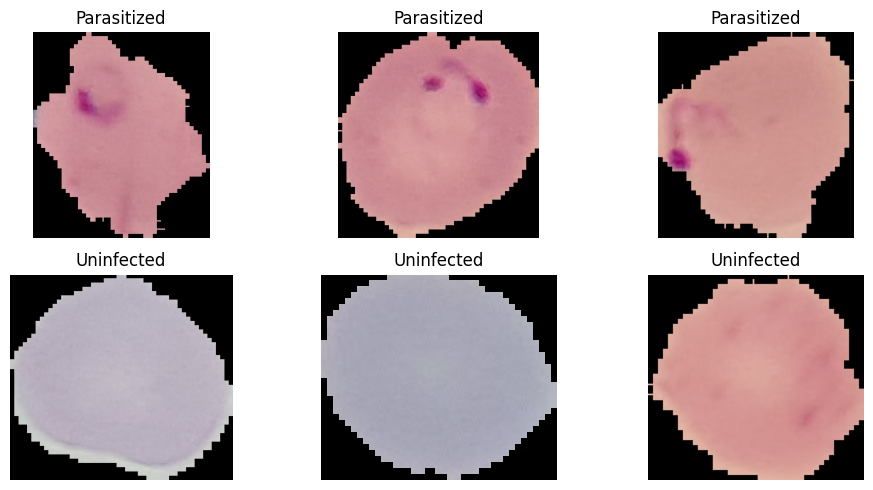

In [ ]:
import os
import glob
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

base_dir = os.path.join(path, 'cell_images', 'cell_images')
if not os.path.exists(base_dir):
    base_dir = os.path.join(path, 'cell_images')

parasitized_dir = os.path.join(base_dir, 'Parasitized')
uninfected_dir = os.path.join(base_dir, 'Uninfected')

parasitized_files = glob.glob(os.path.join(parasitized_dir, '*.png'))
uninfected_files = glob.glob(os.path.join(uninfected_dir, '*.png'))

print(f"Total Parasitized images: {len(parasitized_files)}")
print(f"Total Uninfected images: {len(uninfected_files)}")

# EDA: Show some sample images
plt.figure(figsize=(10, 5))
for i in range(3):
    plt.subplot(2, 3, i + 1)
    img = mpimg.imread(parasitized_files[i])
    plt.imshow(img)
    plt.title('Parasitized')
    plt.axis('off')

    plt.subplot(2, 3, i + 4)
    img = mpimg.imread(uninfected_files[i])
    plt.imshow(img)
    plt.title('Uninfected')
    plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define image dimensions and batch size
IMG_HEIGHT = 64
IMG_WIDTH = 64
BATCH_SIZE = 32

# We separate training and validation generators to apply augmentation ONLY to training data
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    vertical_flip=True,
    validation_split=0.2
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    shuffle=True
)

validation_generator = val_datagen.flow_from_directory(
    base_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    shuffle=False
)

Found 22048 images belonging to 2 classes.
Found 5510 images belonging to 2 classes.


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

# Build an optimized CNN model with regularization
model = Sequential([
    # Block 1
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.2),

    # Block 2
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    # Block 3
    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.3),

    # Dense Classifier
    Flatten(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62, 62, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 29, 29, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,737 (2.61 MB)

 Trainable params: 684,033 (2.61 MB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

EPOCHS = 100

# Configure early stopping with patience of 7 epochs
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    callbacks=[early_stop]
)

Epoch 1/100
689/689 ━━━━━━━━━━━━━━━━━━━━ 76s 96ms/step - accuracy: 0.7994 - loss: 0.4571 - val_accuracy: 0.8777 - val_loss: 0.3081
Epoch 2/100
689/689 ━━━━━━━━━━━━━━━━━━━━ 65s 94ms/step - accuracy: 0.9225 - loss: 0.2235 - val_accuracy: 0.9265 - val_loss: 0.2385
Epoch 3/100
689/689 ━━━━━━━━━━━━━━━━━━━━ 65s 94ms/step - accuracy: 0.9366 - loss: 0.1935 - val_accuracy: 0.9165 - val_loss: 0.2999
Epoch 4/100
689/689 ━━━━━━━━━━━━━━━━━━━━ 65s 94ms/step - accuracy: 0.9386 - loss: 0.1845 - val_accuracy: 0.9339 - val_loss: 0.1967
Epoch 5/100
689/689 ━━━━━━━━━━━━━━━━━━━━ 64s 94ms/step - accuracy: 0.9435 - loss: 0.1755 - val_accuracy: 0.9363 - val_loss: 0.1998
Epoch 6/100
689/689 ━━━━━━━━━━━━━━━━━━━━ 64s 93ms/step - accuracy: 0.9442 - loss: 0.1766 - val_accuracy: 0.9377 - val_loss: 0.1767
Epoch 7/100
689/689 ━━━━━━━━━━━━━━━━━━━━ 65s 94ms/step - accuracy: 0.9443 - loss: 0.1751 - val_accuracy: 0.9334 - val_loss: 0.1817
Epoch 8/100
689/689 ━━━━━━━━━━━━━━━━━━━━ 64s 93ms/step - accuracy: 0.9468 - loss: 0

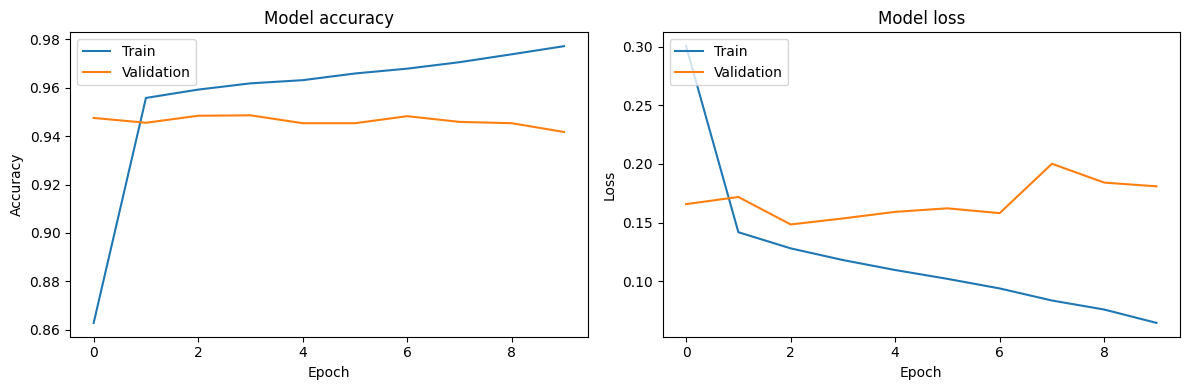

In [ ]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
# import numpy as np
# from google.colab import files
# from tensorflow.keras.preprocessing import image

# print("Upload an image of a cell to predict if it's Parasitized or Uninfected")
# uploaded = files.upload()

# for fn in uploaded.keys():
#     # predict images
#     path = fn
#     img = image.load_img(path, target_size=(IMG_HEIGHT, IMG_WIDTH))

#     # Convert image to array and normalize
#     img_array = image.img_to_array(img)
#     img_array = np.expand_dims(img_array, axis=0)
#     img_array /= 255.0

#     # Make prediction
#     prediction = model.predict(img_array)

#     print(f"\nPrediction for {fn}:")
#     # Our model uses sigmoid, so output is probability of class 1 (Uninfected typically, based on generator order)
#     class_indices = train_generator.class_indices
#     inverted_indices = {v: k for k, v in class_indices.items()}

#     pred_class = inverted_indices[int(np.round(prediction[0][0]))]
#     confidence = prediction[0][0] if pred_class == inverted_indices[1] else 1 - prediction[0][0]

#     print(f"{pred_class} (Confidence: {confidence:.2f})")

#     # Show image
#     plt.imshow(image.load_img(path))
#     plt.axis('off')
#     plt.show()

Upload an image of a cell to predict if it's Parasitized or Uninfected


In [ ]:
# Save the trained model in the recommended native Keras format
model_filename = 'malaria_cnn_model.keras'
model.save(model_filename)
print(f"Model successfully saved as {model_filename}")

# Download the model to your local machine for use in your web app
from google.colab import files
files.download(model_filename)

Model successfully saved as malaria_cnn_model.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 1 & 2. Data Preparation: Class Mapping, 3-Way Split & tf.data Pipeline (128x128)

In [ ]:
import albumentations as A
import cv2
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import os
import glob

# Ensure file lists are loaded in this cell
base_dir = os.path.join(path, 'cell_images', 'cell_images')
if not os.path.exists(base_dir):
    base_dir = os.path.join(path, 'cell_images')

parasitized_dir = os.path.join(base_dir, 'Parasitized')
uninfected_dir = os.path.join(base_dir, 'Uninfected')

parasitized_files = glob.glob(os.path.join(parasitized_dir, '*.png'))
uninfected_files = glob.glob(os.path.join(uninfected_dir, '*.png'))

# 1. Class Mapping: 0 = Uninfected, 1 = Parasitized
filepaths = uninfected_files + parasitized_files
labels = [0] * len(uninfected_files) + [1] * len(parasitized_files)

# 2. Increase Resolution & 3-Way Split (80% Train, 10% Val, 10% Test)
IMG_HEIGHT = 200
IMG_WIDTH = 200
BATCH_SIZE = 32

# First split: 90% Temp (Train+Val), 10% Test
X_temp, X_test, y_temp, y_test = train_test_split(filepaths, labels, test_size=0.1, stratify=labels, random_state=42)
# Second split: From Temp, take ~11.11% for Val (which is 10% of total), remaining 88.89% for Train (80% of total)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1111, stratify=y_temp, random_state=42)

print(f"Train size: {len(X_train)}, Validation size: {len(X_val)}, Test size: {len(X_test)}")

# 3. Domain-Specific Data Augmentation with Albumentations
train_transform = A.Compose([
    A.Resize(IMG_HEIGHT, IMG_WIDTH),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.Sharpen(alpha=(0.2, 0.5), lightness=(0.5, 1.0), p=0.5),
    A.Normalize(mean=(0.0, 0.0, 0.0), std=(1.0, 1.0, 1.0)) # Rescale 1./255
])

val_test_transform = A.Compose([
    A.Resize(IMG_HEIGHT, IMG_WIDTH),
    A.Normalize(mean=(0.0, 0.0, 0.0), std=(1.0, 1.0, 1.0))
])

def process_image(filepath, label, is_train=True):
    img = cv2.imread(filepath.decode('utf-8'))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if is_train:
        aug = train_transform(image=img)
    else:
        aug = val_test_transform(image=img)
    return aug['image'].astype(np.float32), np.float32(label)

def tf_process_train(filepath, label):
    img, lbl = tf.numpy_function(func=lambda f, l: process_image(f, l, True), inp=[filepath, label], Tout=[tf.float32, tf.float32])
    img.set_shape([IMG_HEIGHT, IMG_WIDTH, 3])
    lbl.set_shape([])
    return img, lbl

def tf_process_val_test(filepath, label):
    img, lbl = tf.numpy_function(func=lambda f, l: process_image(f, l, False), inp=[filepath, label], Tout=[tf.float32, tf.float32])
    img.set_shape([IMG_HEIGHT, IMG_WIDTH, 3])
    lbl.set_shape([])
    return img, lbl

# Build tf.data.Datasets
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train))\
    .map(tf_process_train, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))\
    .map(tf_process_val_test, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))\
    .map(tf_process_val_test, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

Train size: 22046, Validation size: 2756, Test size: 2756


### 4. Medical Metrics, Callbacks, and Model Training

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Set random seed for reproducibility across Python, NumPy, and TensorFlow
tf.keras.utils.set_random_seed(42)

# Build the specified 3-block CNN
new_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.2),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.3),

    Flatten(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# Compile with clinical metrics
new_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.FalseNegatives(name='fn')
    ]
)

# Configure Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1)
checkpoint = ModelCheckpoint('malaria_best_model.keras', monitor='val_recall', mode='max', save_best_only=True, verbose=1)

# Train with Class Weights penalizing False Negatives
EPOCHS = 80

history_new = new_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr, checkpoint],
    class_weight={0: 1.0, 1: 2.0} # Penalize misses on Parasitized (1) more
)

Epoch 1/80


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


689/689 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7041 - auc: 0.7724 - fn: 1000.6052 - loss: 0.8849 - precision: 0.6751 - recall: 0.7758
Epoch 1: val_recall improved from None to 0.91074, saving model to malaria_best_model.keras

Epoch 1: finished saving model to malaria_best_model.keras
689/689 ━━━━━━━━━━━━━━━━━━━━ 54s 64ms/step - accuracy: 0.7991 - auc: 0.8800 - fn: 1590.0000 - loss: 0.6389 - precision: 0.7687 - recall: 0.8558 - val_accuracy: 0.8741 - val_auc: 0.9166 - val_fn: 123.0000 - val_loss: 0.4007 - val_precision: 0.8485 - val_recall: 0.9107 - learning_rate: 0.0010
Epoch 2/80
689/689 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8896 - auc: 0.9458 - fn: 494.5530 - loss: 0.4114 - precision: 0.8761 - recall: 0.9102
Epoch 2: val_recall improved from 0.91074 to 0.92816, saving model to malaria_best_model.keras

Epoch 2: finished saving model to malaria_best_model.keras
689/689 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.8978 - auc: 0.9503 - fn: 957.0000 - loss: 0.3904

KeyboardInterrupt: 

### 5. Comprehensive Evaluation & Threshold Tuning on Test Set

87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step


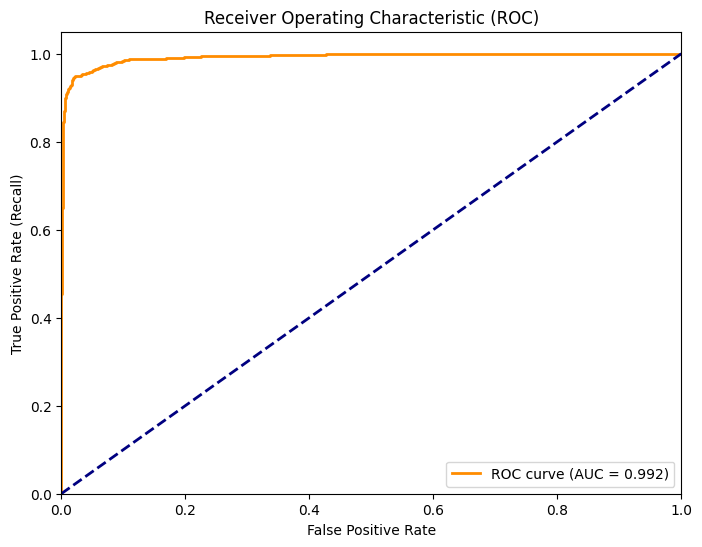


Metrics at Threshold: 0.5
                 precision    recall  f1-score   support

 Uninfected (0)       0.96      0.96      0.96      1378
Parasitized (1)       0.96      0.96      0.96      1378

       accuracy                           0.96      2756
      macro avg       0.96      0.96      0.96      2756
   weighted avg       0.96      0.96      0.96      2756



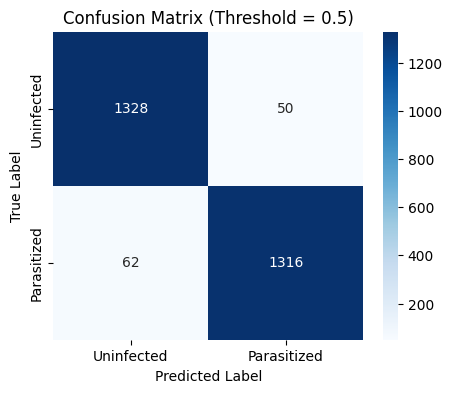


Metrics at Threshold: 0.3
                 precision    recall  f1-score   support

 Uninfected (0)       0.97      0.93      0.95      1378
Parasitized (1)       0.93      0.97      0.95      1378

       accuracy                           0.95      2756
      macro avg       0.95      0.95      0.95      2756
   weighted avg       0.95      0.95      0.95      2756



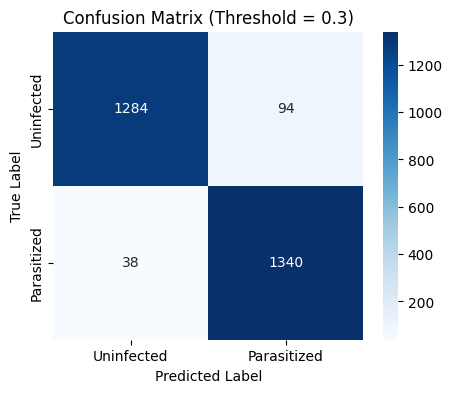

In [ ]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# Predict probabilities on the held-out test set
y_pred_prob = new_model.predict(test_ds)
y_true = np.array(y_test)

# --- ROC Curve ---
fpr, tpr, thresholds = roc_curve(y_true, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

# --- Threshold Tuning & Confusion Matrices ---
def evaluate_threshold(threshold, y_true, y_pred_prob):
    y_pred_class = (y_pred_prob >= threshold).astype(int).flatten()
    cm = confusion_matrix(y_true, y_pred_class)

    print(f"\n{'='*40}\nMetrics at Threshold: {threshold}\n{'='*40}")
    print(classification_report(y_true, y_pred_class, target_names=['Uninfected (0)', 'Parasitized (1)']))

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Uninfected', 'Parasitized'],
                yticklabels=['Uninfected', 'Parasitized'])
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.title(f'Confusion Matrix (Threshold = {threshold})')
    plt.show()

# Evaluate Default Threshold
evaluate_threshold(0.50, y_true, y_pred_prob)

# Evaluate Lower Clinical Threshold to minimize False Negatives
evaluate_threshold(0.30, y_true, y_pred_prob)

In [ ]:
# Save the final refactored model in the recommended native Keras format
final_model_filename = 'malaria_refactored_final_model.keras'
new_model.save(final_model_filename)
print(f"Final refactored model successfully saved as {final_model_filename}")

Final refactored model successfully saved as malaria_refactored_final_model.keras


In [ ]:
from google.colab import files
files.download('malaria_refactored_final_model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>